# Check Eye-Tracking Data

This Notebook is to test the eyetracking data and if the labels for the fixations were extracted correctly.

In [3]:
import os
import sys
import warnings
import pandas as pd

sys.path.append("../..")

from data.data_configs import ALL_SUBJECTS, SUBJECTS, ET_DIR
from data.data_testing.check_et_labels_utils import plot_stimulus_for_subject, list_available_stimuli, load_events
from data.data_preparation.label_et_data import get_stimuli_for_subject


warnings.filterwarnings("ignore") 

### Plot Stimuli for subjects to see if the ET data looks correct
- Are the coordinates correct?
- Are the boxes around the planes?
- Are the fixations labels correctly?
- Are there missing fixations?
- etc.

Subject P02
Fixations: total=3, on-target=0, off-target=3


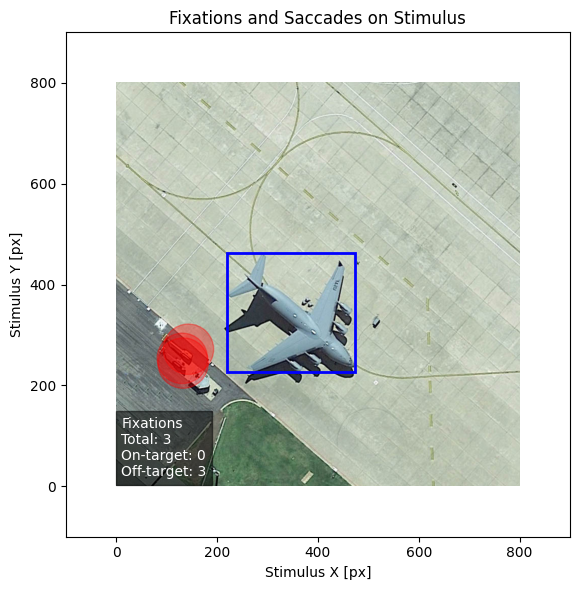

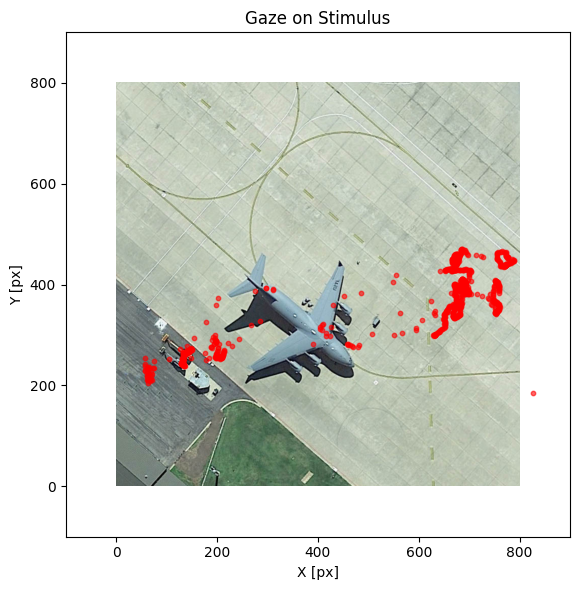

In [8]:
for subj in ALL_SUBJECTS[1:2]:
    print(f"Subject {subj}")
    stimulus = "19024"
    stimulus = "06979"
    plot_stimulus_for_subject(subj, also_gaze=True,stimulus=stimulus, seed = 42)
    break

### Check for zero fixations and where to clean data

Above some images didnt show any fixations, so we check how many trials without fixations stimuli exist per subject. A look at the data tells that some subjects have messed up data. That is, for the Exe tracking many values are missing for some stimuli, therefore we can not use it for further analysis. Subjects with a zero fixation rate above 5% will be removed from the final set of participants.


Also some gaze point for some trials seem to be of so we implemented cleaning...

In [3]:
summary_rows = []
for subj in ALL_SUBJECTS:
    events = load_events(subj)
    available = set(list_available_stimuli(subj))
    event_stims = set(events['stimulus'].dropna().unique().tolist())
    candidate_stims = sorted(event_stims & available)

    zero_fix_stims = []
    for stim in candidate_stims:
        evs = events[events['stimulus'] == stim]
        fix = evs[evs['event_type'] == 'Fixation']
        if len(fix) == 0:
            zero_fix_stims.append(stim)

    total = len(candidate_stims)
    zero_count = len(zero_fix_stims)
    pct_zero = (zero_count / total * 100.0) if total > 0 else 0.0

    summary_rows.append({
        'subject': subj,
        'stimuli': total,
        'zero_fixations': zero_count,
        'pct_zero_fix': round(pct_zero, 1)
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,subject,stimuli,zero_fixations,pct_zero_fix
0,P01,501,0,0.0
1,P02,501,43,8.6
2,P03,501,352,70.3
3,P04,501,493,98.4
4,P05,501,28,5.6
5,P06,501,0,0.0
6,P07,501,0,0.0
7,P08,501,322,64.3
8,P09,501,0,0.0
9,P10,501,20,4.0


In [4]:
# Subjects with >5% zero-fixations
summary_df.loc[summary_df['pct_zero_fix'] > 5, 'subject'].tolist()

['P02',
 'P03',
 'P04',
 'P05',
 'P08',
 'P12',
 'P13',
 'P14',
 'P18',
 'P19',
 'P22',
 'P24',
 'P32',
 'P34']

### Trials after cleaning

Subject P01
Selected random stimulus for P01: 12950
Fixations: total=2, on-target=0, off-target=2


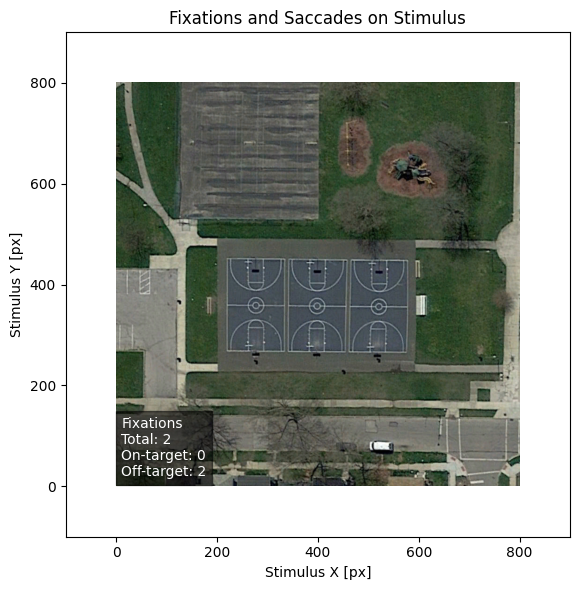

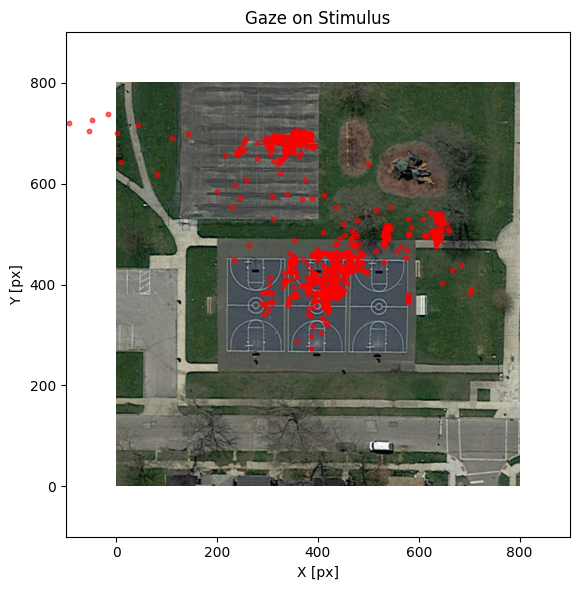

Subject P07
Selected random stimulus for P07: 05486
Fixations: total=15, on-target=11, off-target=4


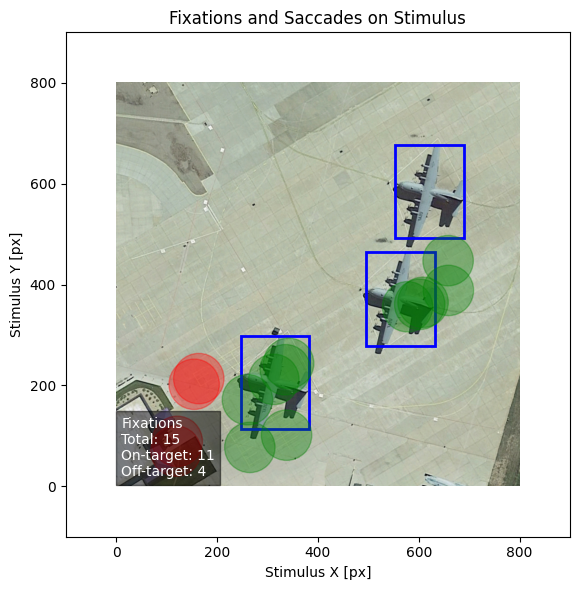

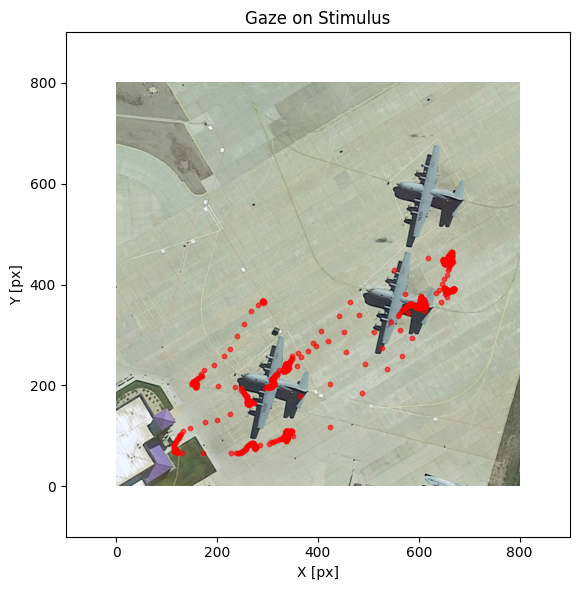

Subject P09
Selected random stimulus for P09: 04501
Fixations: total=6, on-target=4, off-target=2


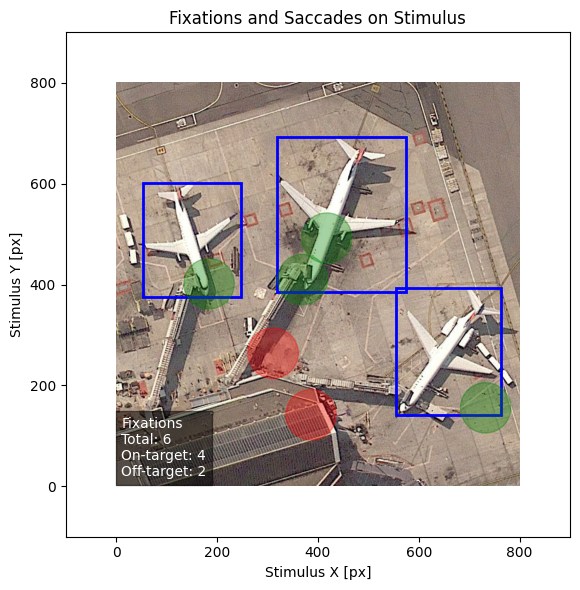

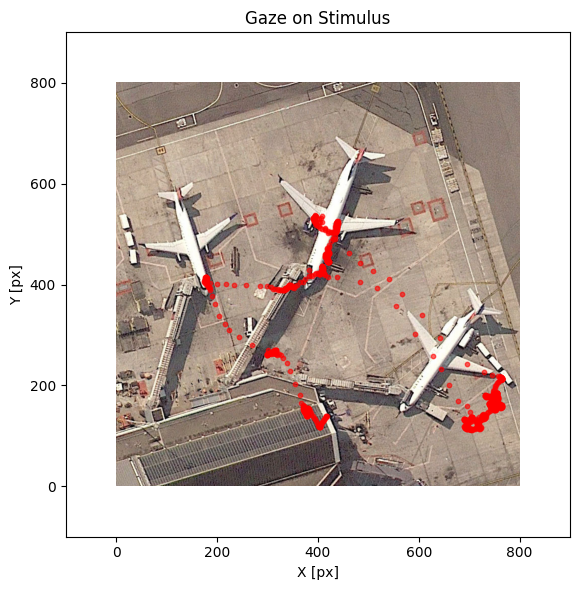

Subject P10
Selected random stimulus for P10: 00029
Fixations: total=9, on-target=8, off-target=1


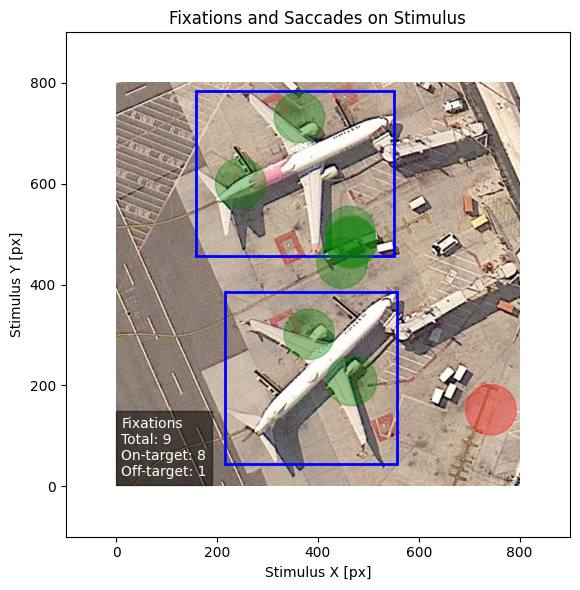

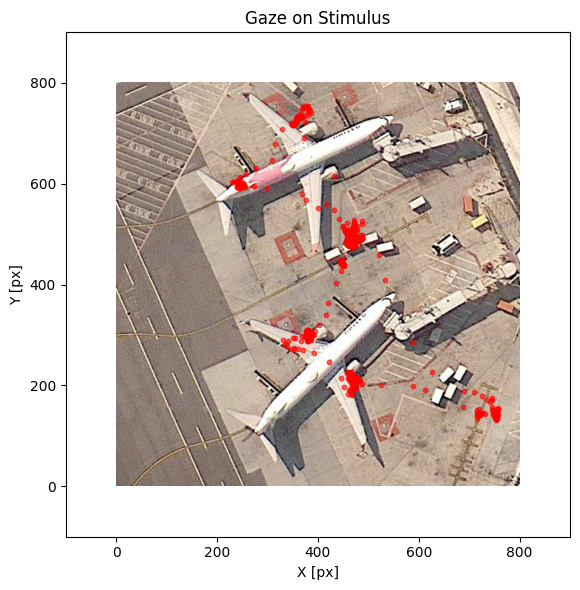

Subject P16
Selected random stimulus for P16: 00823
Fixations: total=8, on-target=7, off-target=1


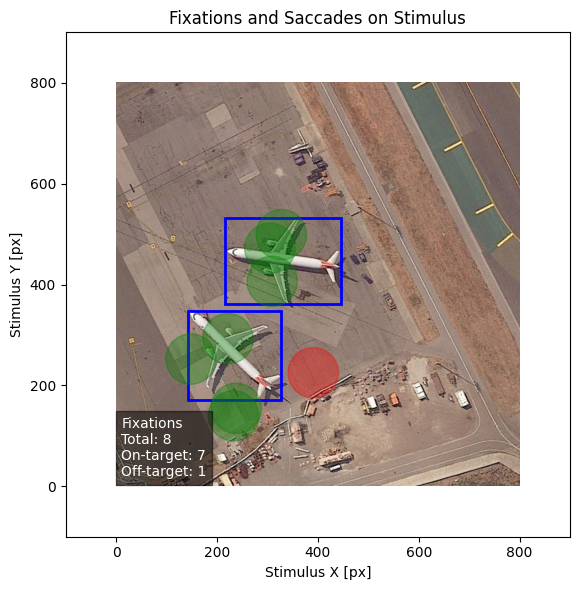

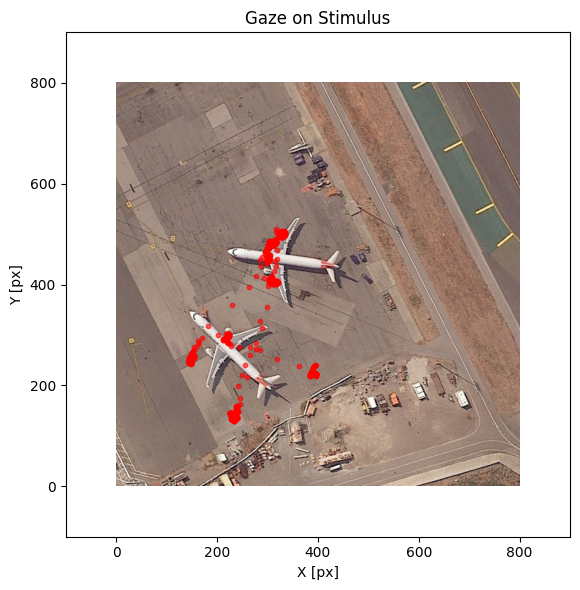

In [6]:
for subj in SUBJECTS[:5]:
    print(f"Subject {subj}")
    plot_stimulus_for_subject(subj, also_gaze=True, seed = 42, selected=True)

### Check fixation duration stats

In [11]:
import pandas as pd

all_fixations = []

for subj in SUBJECTS:
    events = load_events(subj)
    fixations = events[events["event_type"] == "Fixation"].copy()
    fixations["subject_id"] = subj
    all_fixations.append(fixations)

fixations_df = pd.concat(all_fixations, ignore_index=True)


In [12]:
fix_on  = fixations_df[fixations_df["fixation_on_airplane"] == True]
fix_off = fixations_df[fixations_df["fixation_on_airplane"] == False]


In [13]:
def describe_duration(df):
    return pd.Series({
        "count": len(df),
        "mean_ms": df["duration_ms"].mean(),
        "median_ms": df["duration_ms"].median(),
        "std_ms": df["duration_ms"].std(),
        "min_ms": df["duration_ms"].min(),
        "max_ms": df["duration_ms"].max(),
    })


In [14]:
summary = (
    fixations_df
    .groupby("fixation_on_airplane")
    .apply(describe_duration)
)

summary.index = ["Off airplane", "On airplane"]
print(summary.round(2))

                count  mean_ms  median_ms    std_ms  min_ms      max_ms
Off airplane  34944.0   372.71     227.85  10473.27     0.0  1883501.96
On airplane   28161.0   552.87     264.00  18704.39     0.0  1821083.11


In [15]:
all_events = []

for subj in SUBJECTS:
    events = load_events(subj)
    events["subject_id"] = subj
    all_events.append(events)

df = pd.concat(all_fixations, ignore_index=True)


In [16]:
import pandas as pd
import numpy as np

# --------------------------
# Load CSV
# --------------------------

# Sort by stimulus and start_time to keep temporal order
df = df.sort_values(["stimulus", "start_time"]).reset_index(drop=True)

# --------------------------
# Compute saccade amplitude & velocity
# --------------------------
saccades = df[df["event_type"] == "Saccade"].copy()

# Compute only if coordinates exist
def compute_saccade_features(row):
    if pd.notna(row["start_x"]) and pd.notna(row["end_x"]):
        dx = row["end_x"] - row["start_x"]
        dy = row["end_y"] - row["start_y"]
        amp = np.sqrt(dx**2 + dy**2)
        vel = amp / row["duration_ms"] if row["duration_ms"] > 0 else np.nan
    else:
        amp = np.nan
        vel = np.nan
    return pd.Series({"sacc_amp": amp, "sacc_vel": vel})

saccades[["sacc_amp", "sacc_vel"]] = saccades.apply(compute_saccade_features, axis=1)

# --------------------------
# Prepare fixations
# --------------------------
fixations = df[df["event_type"] == "Fixation"].copy()
fixations["prev_sacc_amp"] = np.nan
fixations["prev_sacc_vel"] = np.nan
fixations["next_sacc_amp"] = np.nan
fixations["next_sacc_vel"] = np.nan

# --------------------------
# Add previous & next saccade info per stimulus
# --------------------------
for stim in df["stimulus"].unique():
    stim_events = df[df["stimulus"] == stim].sort_values("start_time").reset_index()
    stim_sacc = saccades[saccades["stimulus"] == stim]

    fix_locs = stim_events[stim_events["event_type"] == "Fixation"].index

    for idx in fix_locs:
        # Previous saccade
        prev_sacc_idx = stim_events.loc[:idx-1][stim_events["event_type"] == "Saccade"].index
        if len(prev_sacc_idx) > 0:
            prev_idx = prev_sacc_idx[-1]
            srow = stim_sacc[stim_sacc["start_time"] == stim_events.loc[prev_idx, "start_time"]]
            if not srow.empty:
                fixations.loc[stim_events.loc[idx, "index"], "prev_sacc_amp"] = srow["sacc_amp"].values[0]
                fixations.loc[stim_events.loc[idx, "index"], "prev_sacc_vel"] = srow["sacc_vel"].values[0]

        # Next saccade
        next_sacc_idx = stim_events.loc[idx+1:][stim_events["event_type"] == "Saccade"].index
        if len(next_sacc_idx) > 0:
            next_idx = next_sacc_idx[0]
            srow = stim_sacc[stim_sacc["start_time"] == stim_events.loc[next_idx, "start_time"]]
            if not srow.empty:
                fixations.loc[stim_events.loc[idx, "index"], "next_sacc_amp"] = srow["sacc_amp"].values[0]
                fixations.loc[stim_events.loc[idx, "index"], "next_sacc_vel"] = srow["sacc_vel"].values[0]

# --------------------------
# Descriptive statistics
# --------------------------
features = ["duration_ms", "prev_sacc_amp", "prev_sacc_vel", "next_sacc_amp", "next_sacc_vel"]
summary = fixations.groupby("fixation_on_airplane")[features].agg(["count","mean","median","std","min","max"])
summary.index = ["Off airplane","On airplane"]
print(summary.round(2))

ValueError: Columns must be same length as key